<style>
h1, h2, h3, h4, h5, h6, th, strong, b,
.jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2,
.jp-RenderedHTMLCommon h3, .jp-RenderedHTMLCommon th {
  font-weight: 400 !important;
}
</style>

# Modern Optics Lab 3 (Hyun Seo Lee, Zongren Zhang)
## 3D PSF, OTF, and Pupil Engineering

Fluorescent microspheres were used to measure the 3D PSF and OTF. Results from an open pupil (1), horizontal slit (3), and central obstruction (4) were compared with scalar diffraction simulations.

### 1. Optical setup and acquisition

The detection path includes an objective, emission filter, 100 mm lens, and Thorlabs DCC3240C camera. At 5× magnification, 5.3 µm camera pixels correspond to 1.06 µm at the sample. Axial scanning used nominal 1 µm steps, with three exposures per position.

The simulation used a 25 mm open pupil (1), a 20 × 0.5 mm slit (3), and an obstructed pupil with a 2 mm central stop (4), at an assumed wavelength of 532 nm. Some aperture dimensions were estimated from the drawing.

#### Experimental setup

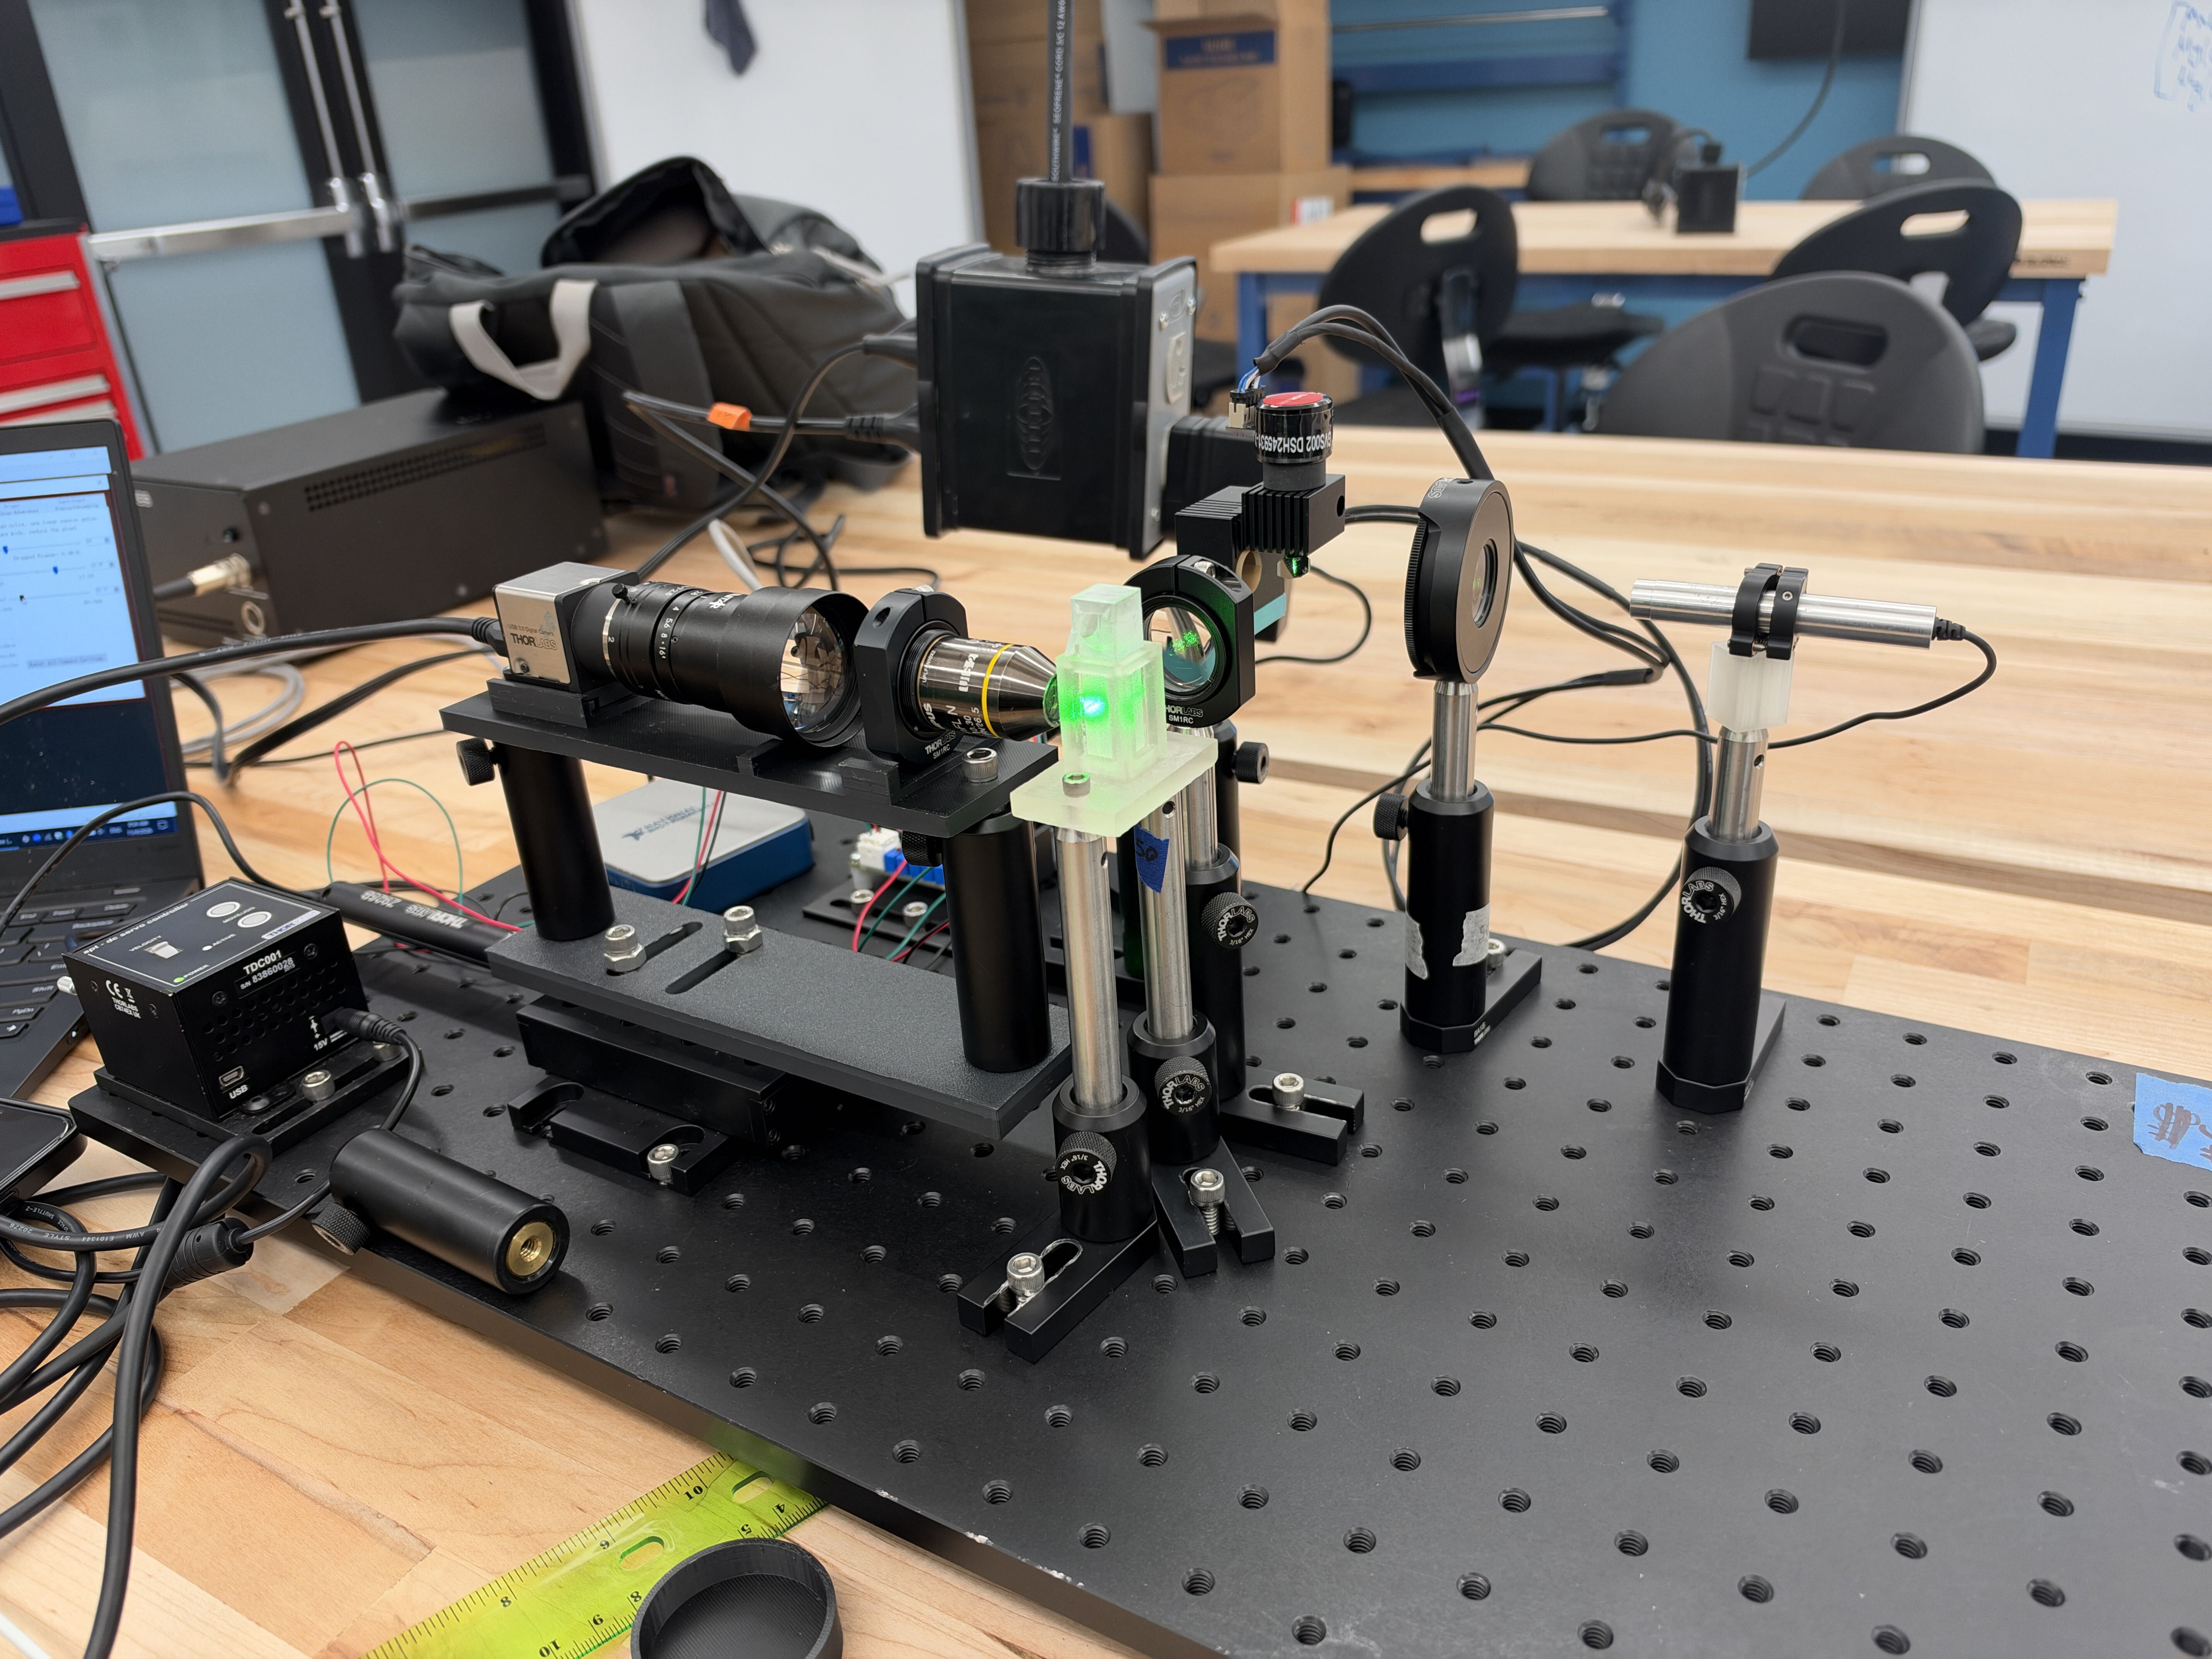

In [3]:
# Load this figure from the local Lab 3 Data folder (run on your Windows PC).
from IPython.display import Image, display
display(Image(filename=r'C:\Users\zhang\PycharmProjects\PythonProject\modern_optics\Lab 3\Data\setup.jpg', width=1000))

*Figure 1. Experimental setup for 3D PSF acquisition, showing the illumination, objective/imaging arm, camera, and translation hardware.*

#### Galvo scanning-mirror calibration

To coordinate the **galvo scanning mirror** with the **imaging-arm positioner offset**, we recorded the positioner reading (mm) at nine applied galvo voltages (V). The measured points were fit by linear least squares. The calibration measurements and fitted relation are shown below.

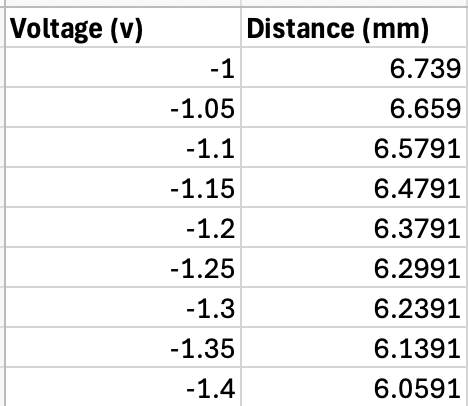

In [4]:
# Load this figure from the local Lab 3 Data folder (run on your Windows PC).
from IPython.display import Image, display
display(Image(filename=r'C:\Users\zhang\PycharmProjects\PythonProject\modern_optics\Lab 3\Data\galvo_table.png', width=460))

*Figure 2a. Measured galvo control voltage and corresponding imaging-arm positioner readings.*

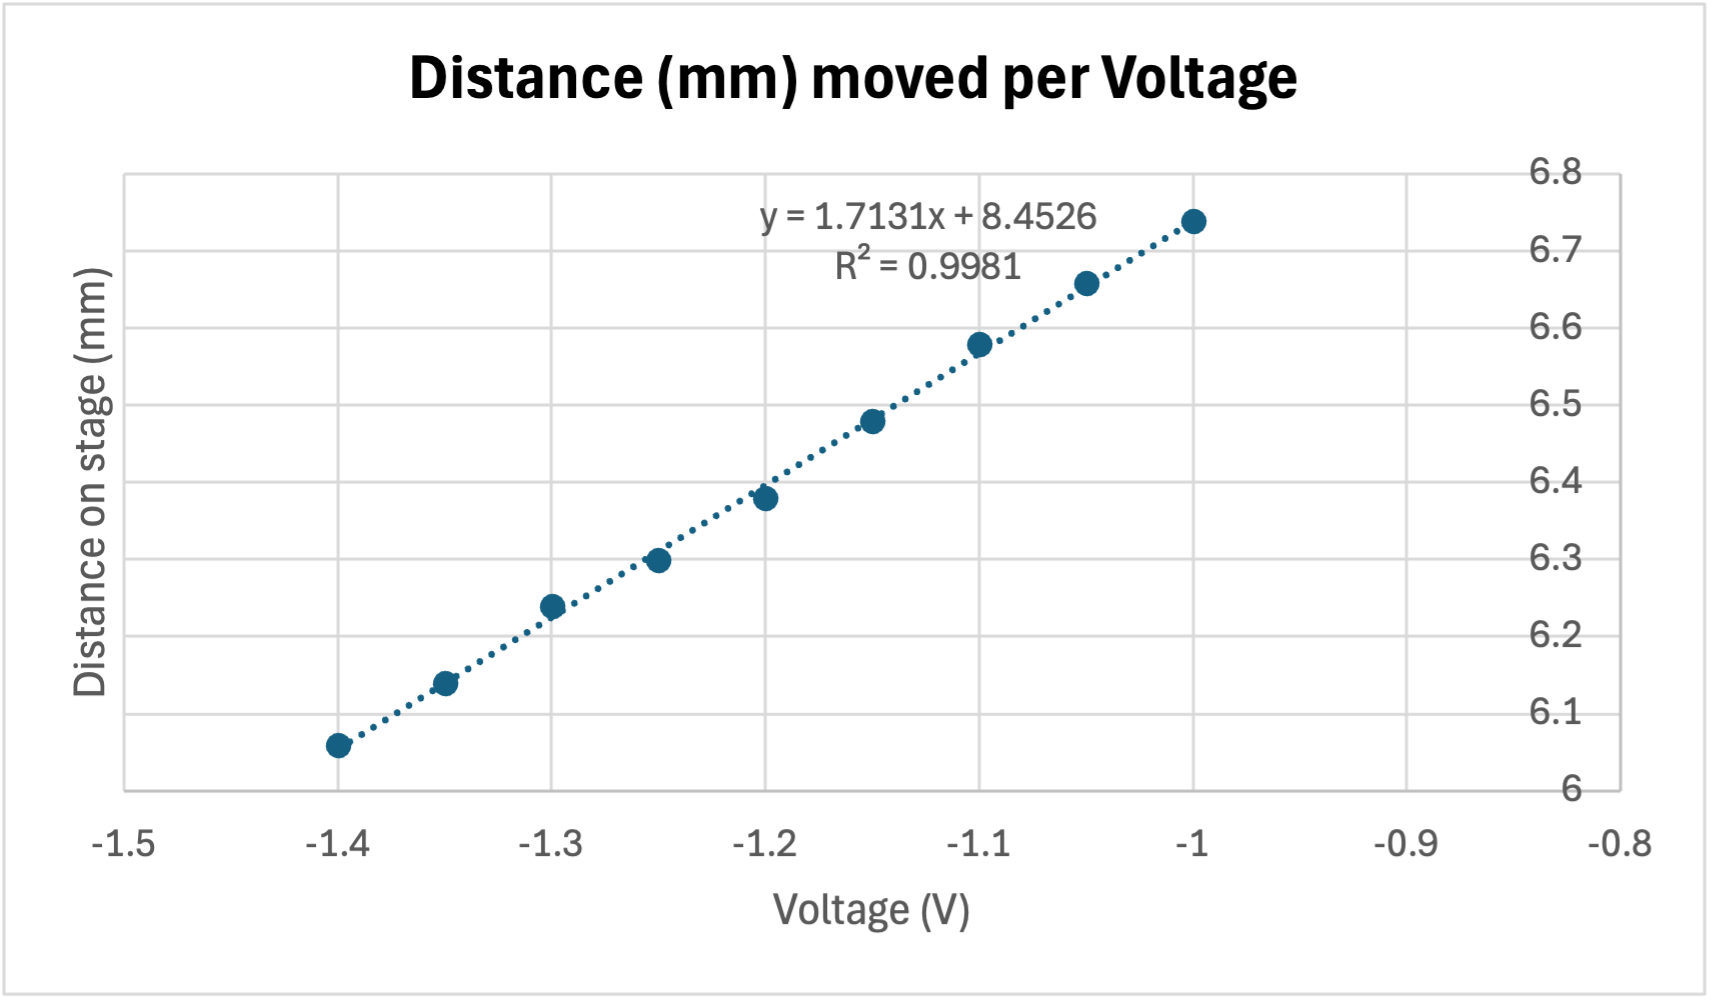

In [5]:
# Load this figure from the local Lab 3 Data folder (run on your Windows PC).
from IPython.display import Image, display
display(Image(filename=r'C:\Users\zhang\PycharmProjects\PythonProject\modern_optics\Lab 3\Data\galvo_fit.png', width=980))

*Figure 2b. Linear calibration of imaging-arm positioner reading against galvo control voltage.*

The fitted relationship is

$$
d_{\mathrm{positioner}}\,(\mathrm{mm})
=1.7131\,V_{\mathrm{galvo}}\,(\mathrm{V})+8.4526,
\qquad R^2=0.9981.
$$

Thus, for a relative positioner displacement $\Delta d$, the corresponding galvo voltage adjustment is

$$
\Delta V_{\mathrm{galvo}}=\frac{\Delta d}{1.7131\ \mathrm{mm/V}}.
$$

For a **1 µm** positioner step, this corresponds to about **0.584 mV**. This relation is based on the measured range of **−1.40 to −1.00 V** and is used to coordinate the galvo scan with the imaging-arm offset.

In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tifffile
from scipy.ndimage import gaussian_filter
from scipy.signal.windows import tukey
from IPython.display import display, Image

# Local Windows folder containing Data/, PSF_comparison/, and simulation outputs.
root = Path(r'C:\Users\zhang\PycharmProjects\PythonProject\modern_optics\Lab 3')
print(f'Analysis data folder: {root}')

dxy_um, dz_um = 5.3 / 5, 1.0
folders = {
    1: ('Open pupil', 'cropped_no aperture'),
    3: ('Horizontal slit', 'cropped_center horizontal aperture'),
    4: ('Central obstruction', 'cropped_center block aperture 2'),
}

Analysis data folder: C:\Users\zhang\PycharmProjects\PythonProject\modern_optics\Lab 3


### 2. Experimental 3D PSF and OTF

Each fluorescent bead approximates a point emitter. The 3D OTF is the normalized 3D Fourier transform of the measured PSF:

$$
H(f_x,f_y,f_z)=\frac{\mathcal{F}_{3D}\{h(x,y,z)\}}{\mathcal{F}_{3D}\{h(x,y,z)\}(0,0,0)}.
$$

The next figure shows the central **XY, YZ, and XZ planes** of each experimental 3D PSF. Their common origin is the peak of the smoothed PSF volume. Three successive TIFF frames are averaged per nominal axial position, then background-subtracted; missing frame indices make the axial reconstruction approximate.

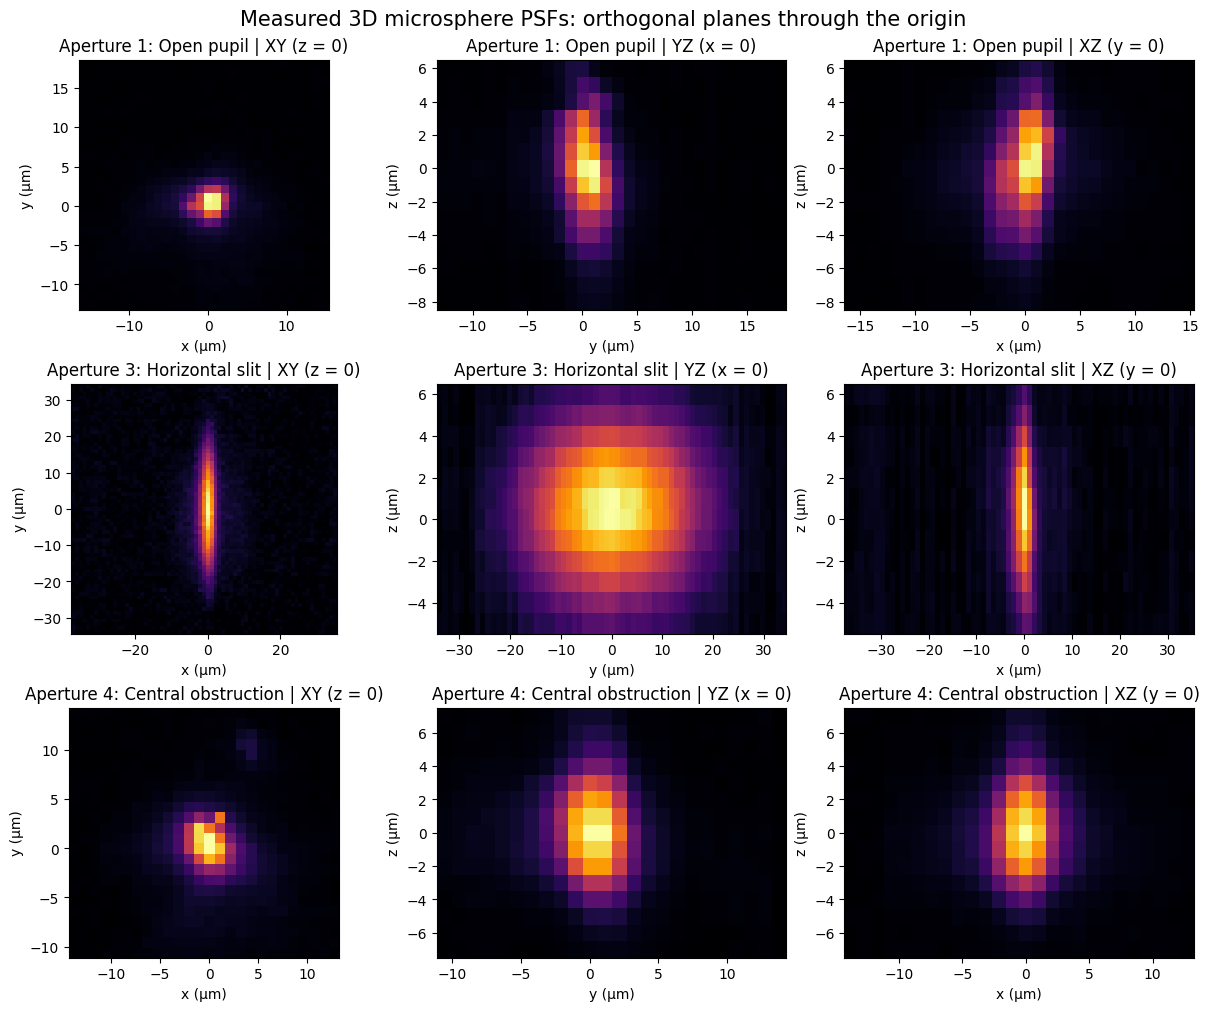

In [7]:
raw_stacks, grouped_psf, otf3d = {}, {}, {}
fig, ax = plt.subplots(3, 3, figsize=(12, 10), layout='constrained')

for r, (ap, (label, folder)) in enumerate(folders.items()):
    raw = tifffile.imread(root / 'Data' / folder / 'cropped_1.tif').astype(float)
    raw_stacks[ap] = raw
    n = len(raw) // 3
    vol = raw[:3*n].reshape(n, 3, *raw.shape[1:]).mean(axis=1)
    bg = np.percentile(vol, 5, axis=(1, 2))
    vol = np.maximum(vol - bg[:, None, None], 0)
    grouped_psf[ap] = vol

    # Set (x, y, z) = (0, 0, 0) at the bead's peak intensity.
    smooth = gaussian_filter(vol, sigma=(0, .8, .8))
    iz, iy, ix = np.unravel_index(np.argmax(smooth), smooth.shape)
    nz, ny, nx = vol.shape
    xlim = [(-ix - .5)*dxy_um, (nx - ix - .5)*dxy_um]
    ylim = [(-iy - .5)*dxy_um, (ny - iy - .5)*dxy_um]
    zlim = [(-iz - .5)*dz_um, (nz - iz - .5)*dz_um]
    vmax = vol.max()  # common intensity scale for all three planes of this aperture

    # All three sections pass through the same PSF origin.
    ax[r, 0].imshow(vol[iz, :, :], origin='lower', cmap='inferno',
                    extent=[*xlim, *ylim], vmin=0, vmax=vmax, aspect='equal')
    ax[r, 1].imshow(vol[:, :, ix], origin='lower', cmap='inferno',
                    extent=[*ylim, *zlim], vmin=0, vmax=vmax, aspect='auto')
    ax[r, 2].imshow(vol[:, iy, :], origin='lower', cmap='inferno',
                    extent=[*xlim, *zlim], vmin=0, vmax=vmax, aspect='auto')

    ax[r, 0].set(xlabel='x (µm)', ylabel='y (µm)',
                 title=f'Aperture {ap}: {label} | XY (z = 0)')
    ax[r, 1].set(xlabel='y (µm)', ylabel='z (µm)',
                 title=f'Aperture {ap}: {label} | YZ (x = 0)')
    ax[r, 2].set(xlabel='x (µm)', ylabel='z (µm)',
                 title=f'Aperture {ap}: {label} | XZ (y = 0)')

plt.suptitle('Measured 3D microsphere PSFs: orthogonal planes through the origin', fontsize=15)
plt.show()

Figure 3. Central XY, YZ, and XZ slices through each measured PSF peak. The origin is the smoothed intensity maximum; z spacing is nominally 1 µm. All three sections of a given aperture share the same intensity scale.

For the 3D OTF, consecutive groups of three frames were averaged and background-subtracted. A boundary window reduced FFT artifacts. The plots show central slices of normalized 3D OTF magnitude.

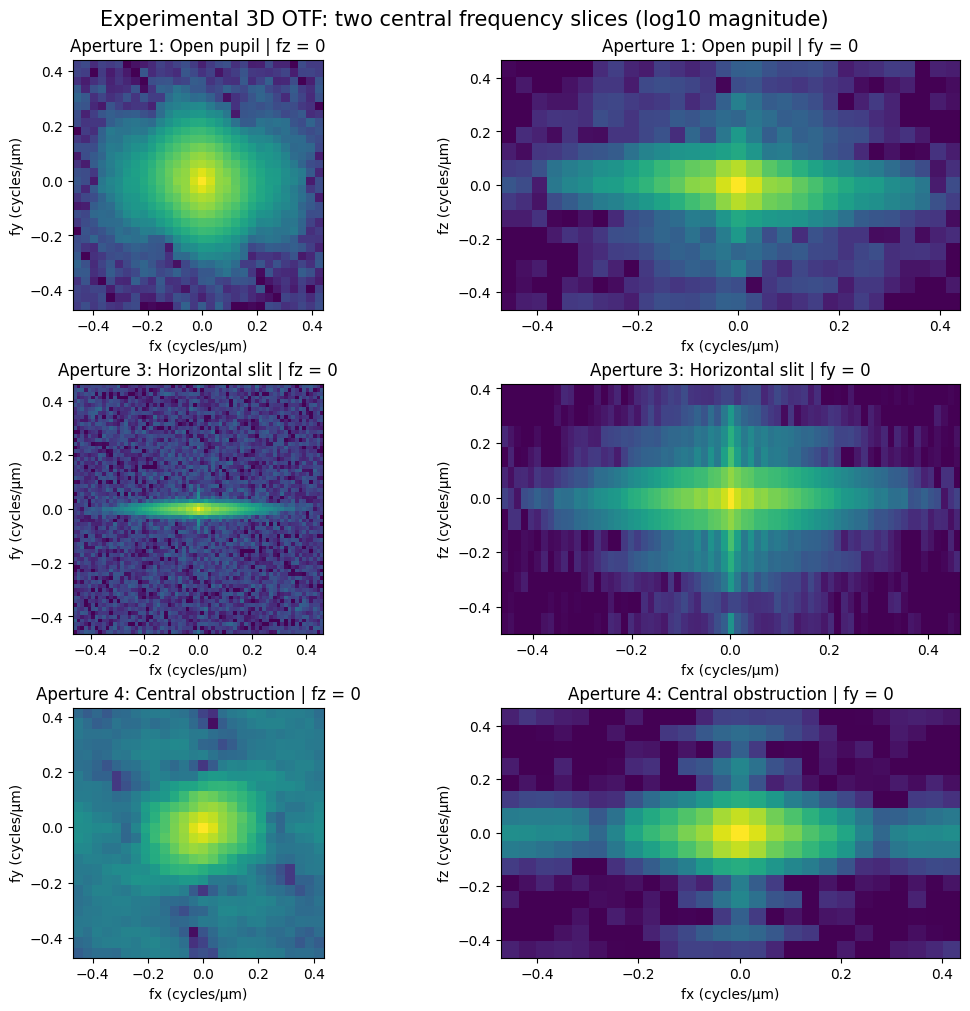

In [8]:
fig, ax = plt.subplots(3, 2, figsize=(10, 10), layout='constrained')
for r, (ap, (label, _)) in enumerate(folders.items()):
    vol = grouped_psf[ap]
    nz, ny, nx = vol.shape
    window = (tukey(nz, .25)[:,None,None] *
              tukey(ny, .25)[None,:,None] *
              tukey(nx, .25)[None,None,:])
    H = np.abs(np.fft.fftshift(np.fft.fftn(vol * window)))
    H /= max(H[nz//2, ny//2, nx//2], 1e-12)
    otf3d[ap] = H
    fx = np.fft.fftshift(np.fft.fftfreq(nx, dxy_um))
    fy = np.fft.fftshift(np.fft.fftfreq(ny, dxy_um))
    fz = np.fft.fftshift(np.fft.fftfreq(nz, dz_um))
    ax[r,0].imshow(np.log10(np.maximum(H[nz//2], 1e-3)), origin='lower',
        extent=[fx[0],fx[-1],fy[0],fy[-1]],cmap='viridis',vmin=-3,vmax=0)
    ax[r,1].imshow(np.log10(np.maximum(H[:,ny//2], 1e-3)), origin='lower',
        extent=[fx[0],fx[-1],fz[0],fz[-1]],cmap='viridis',vmin=-3,vmax=0,aspect='auto')
    ax[r,0].set_title(f'Aperture {ap}: {label} | fz = 0')
    ax[r,1].set_title(f'Aperture {ap}: {label} | fy = 0')
    ax[r,0].set(xlabel='fx (cycles/µm)',ylabel='fy (cycles/µm)')
    ax[r,1].set(xlabel='fx (cycles/µm)',ylabel='fz (cycles/µm)')
plt.suptitle('Experimental 3D OTF: two central frequency slices (log10 magnitude)',fontsize=15)
plt.show()

Figure 4. Experimental 3D OTF magnitude, shown in the lateral and axial frequency planes. The slit reduces the vertical frequency bandwidth. Cropping and uncertain frame positions affect the estimates.

### 3. Numerical ATF, PSF, and OTF

The ATF follows the pupil transmission $P$. The intensity PSF and in-focus OTF are

$$
\mathrm{ATF}\propto P,\qquad
h(x,y;0)\propto|\mathcal{F}^{-1}\{P\}|^2,\qquad
\mathrm{OTF}_{2D}=\frac{\mathcal{F}_{2D}\{h(x,y;0)\}}{\mathcal{F}_{2D}\{h(x,y;0)\}(0,0)}.
$$

The simulated PSFs include pixel integration and pupil defocus. The simulated OTF is an in-focus 2D OTF, whereas Figure 4 shows slices of a measured 3D OTF.

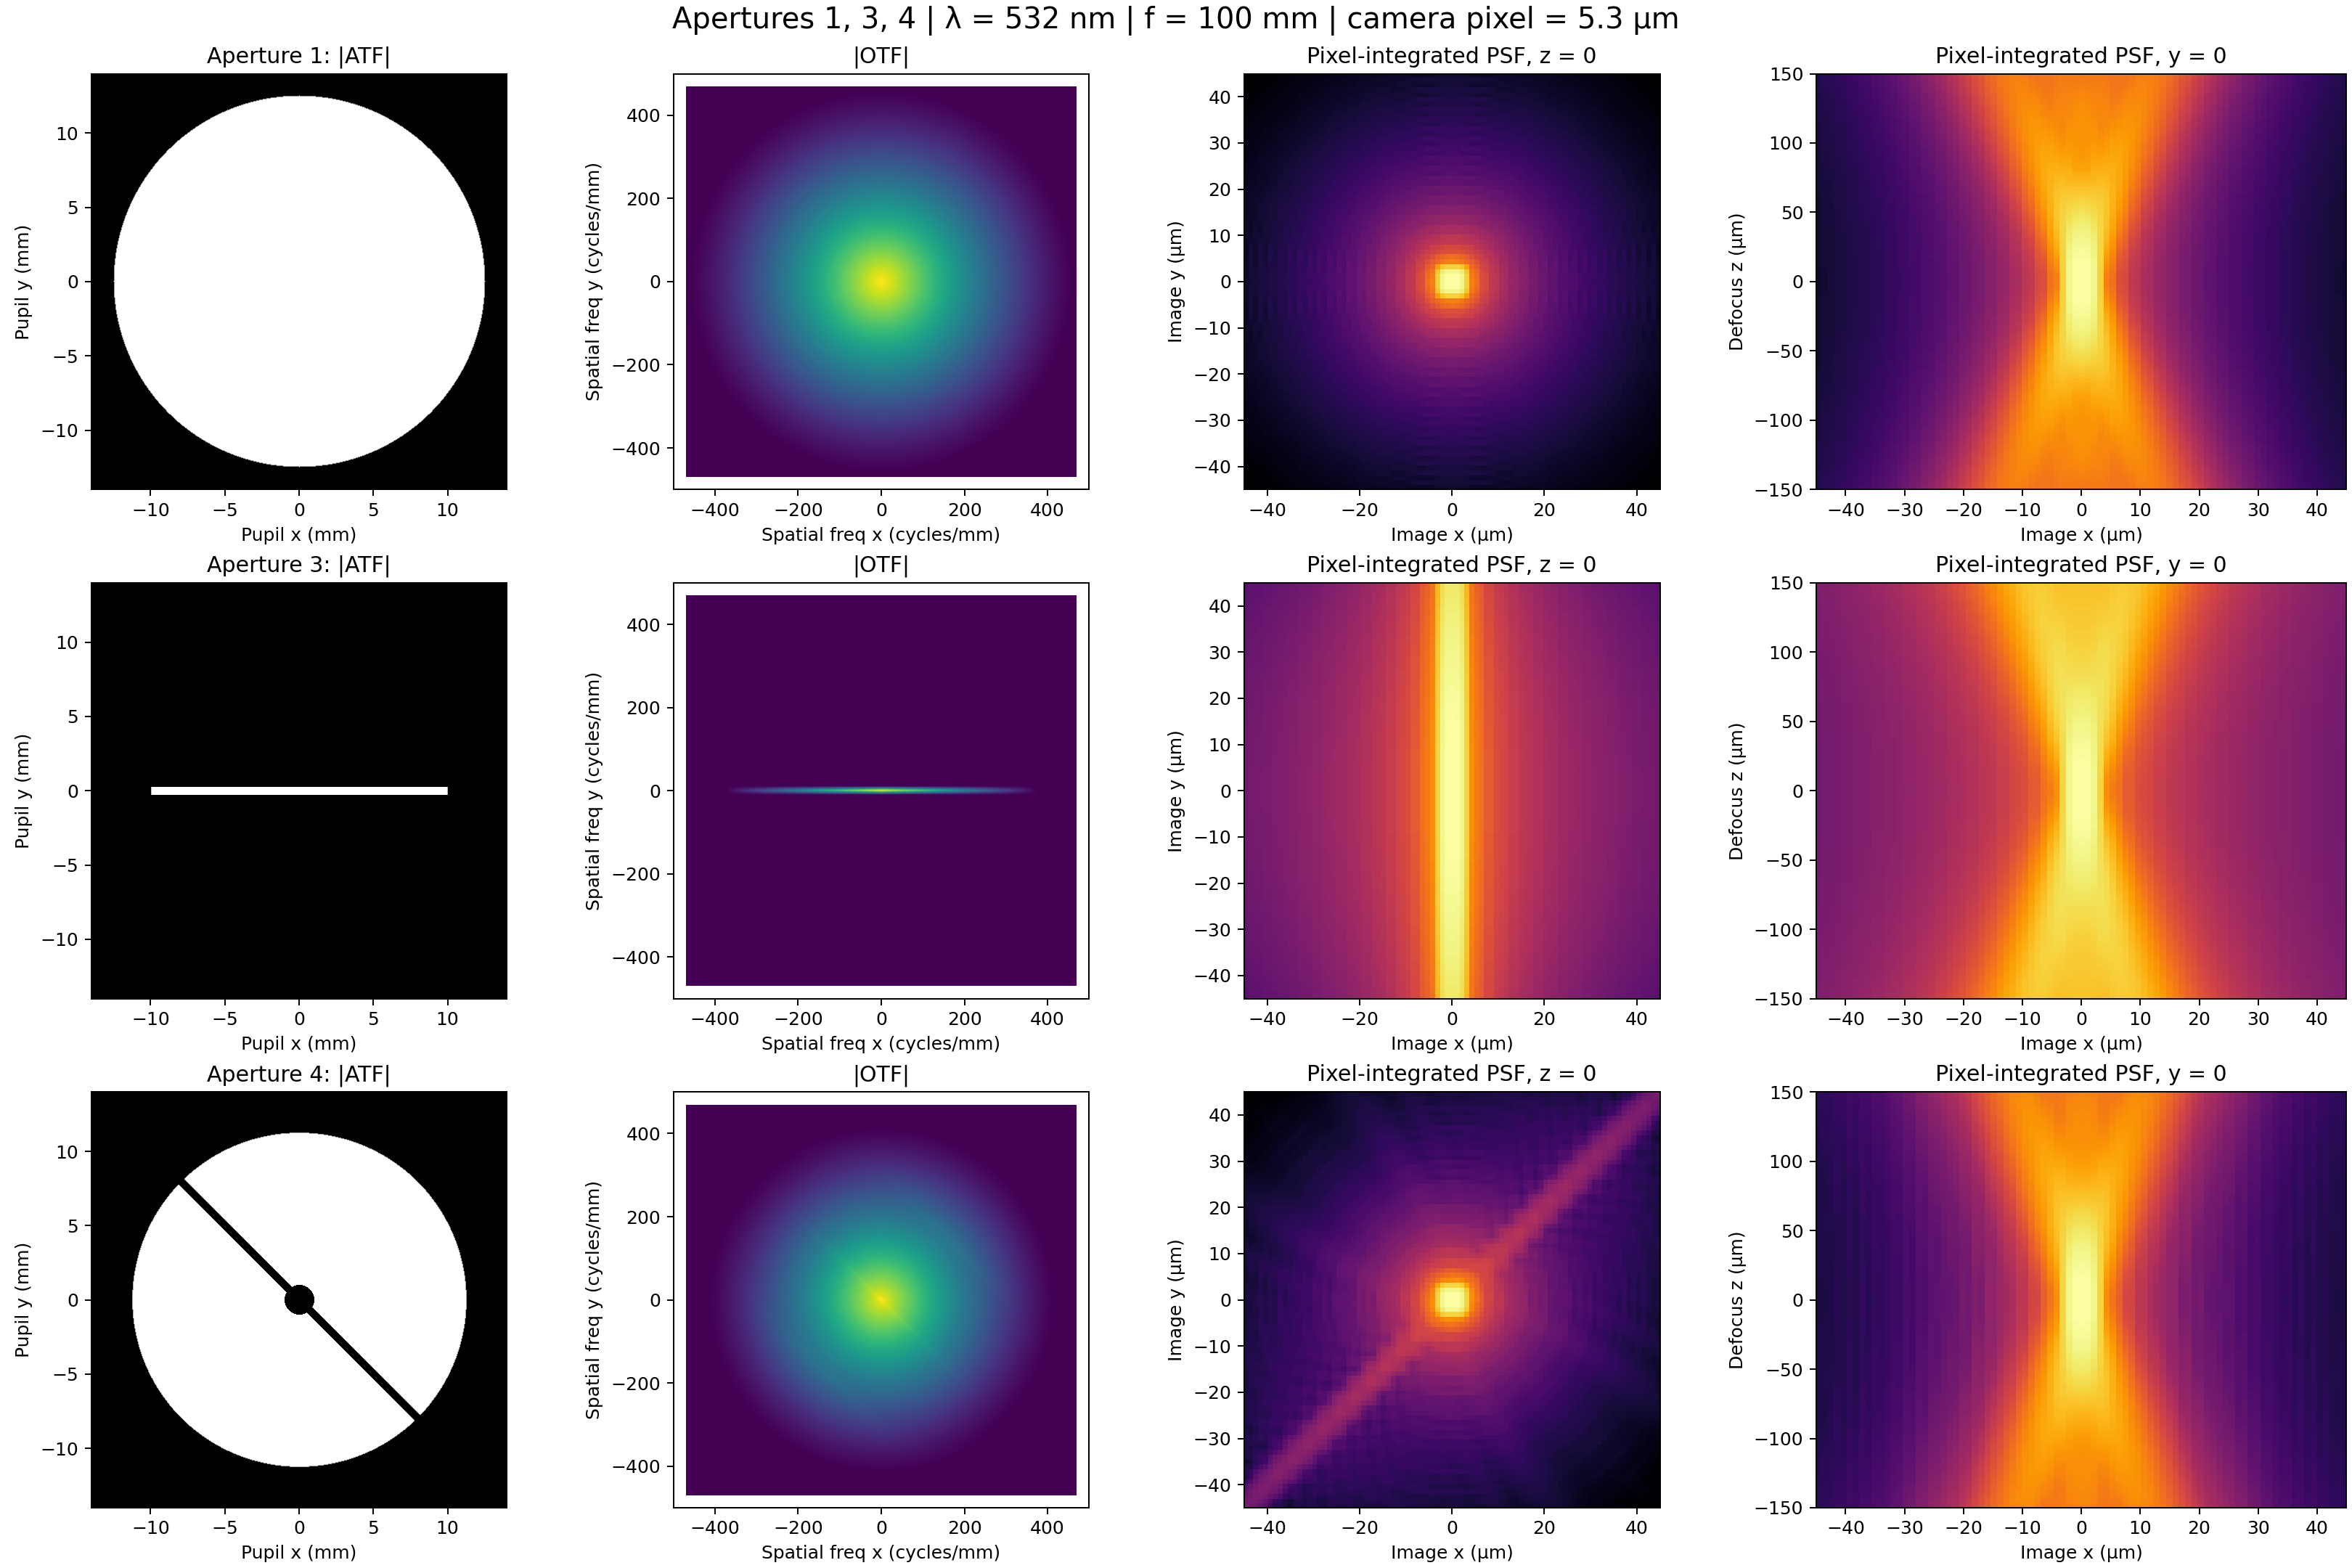

In [9]:
# Existing simulation output: ATF, in-focus OTF, xy PSF, and xz PSF.
display(Image(filename=str(root / 'ATF_PSF_OTF_comparison.png'), width=1050))

Figure 5. Simulated ATF, in-focus OTF, and pixel-integrated xy/xz PSFs for apertures 1, 3, and 4.

### 4. Simulation versus experiment

Three experimental stacks per aperture were aligned and averaged for comparison. Model coordinates were rescaled using the nominal 5× magnification.

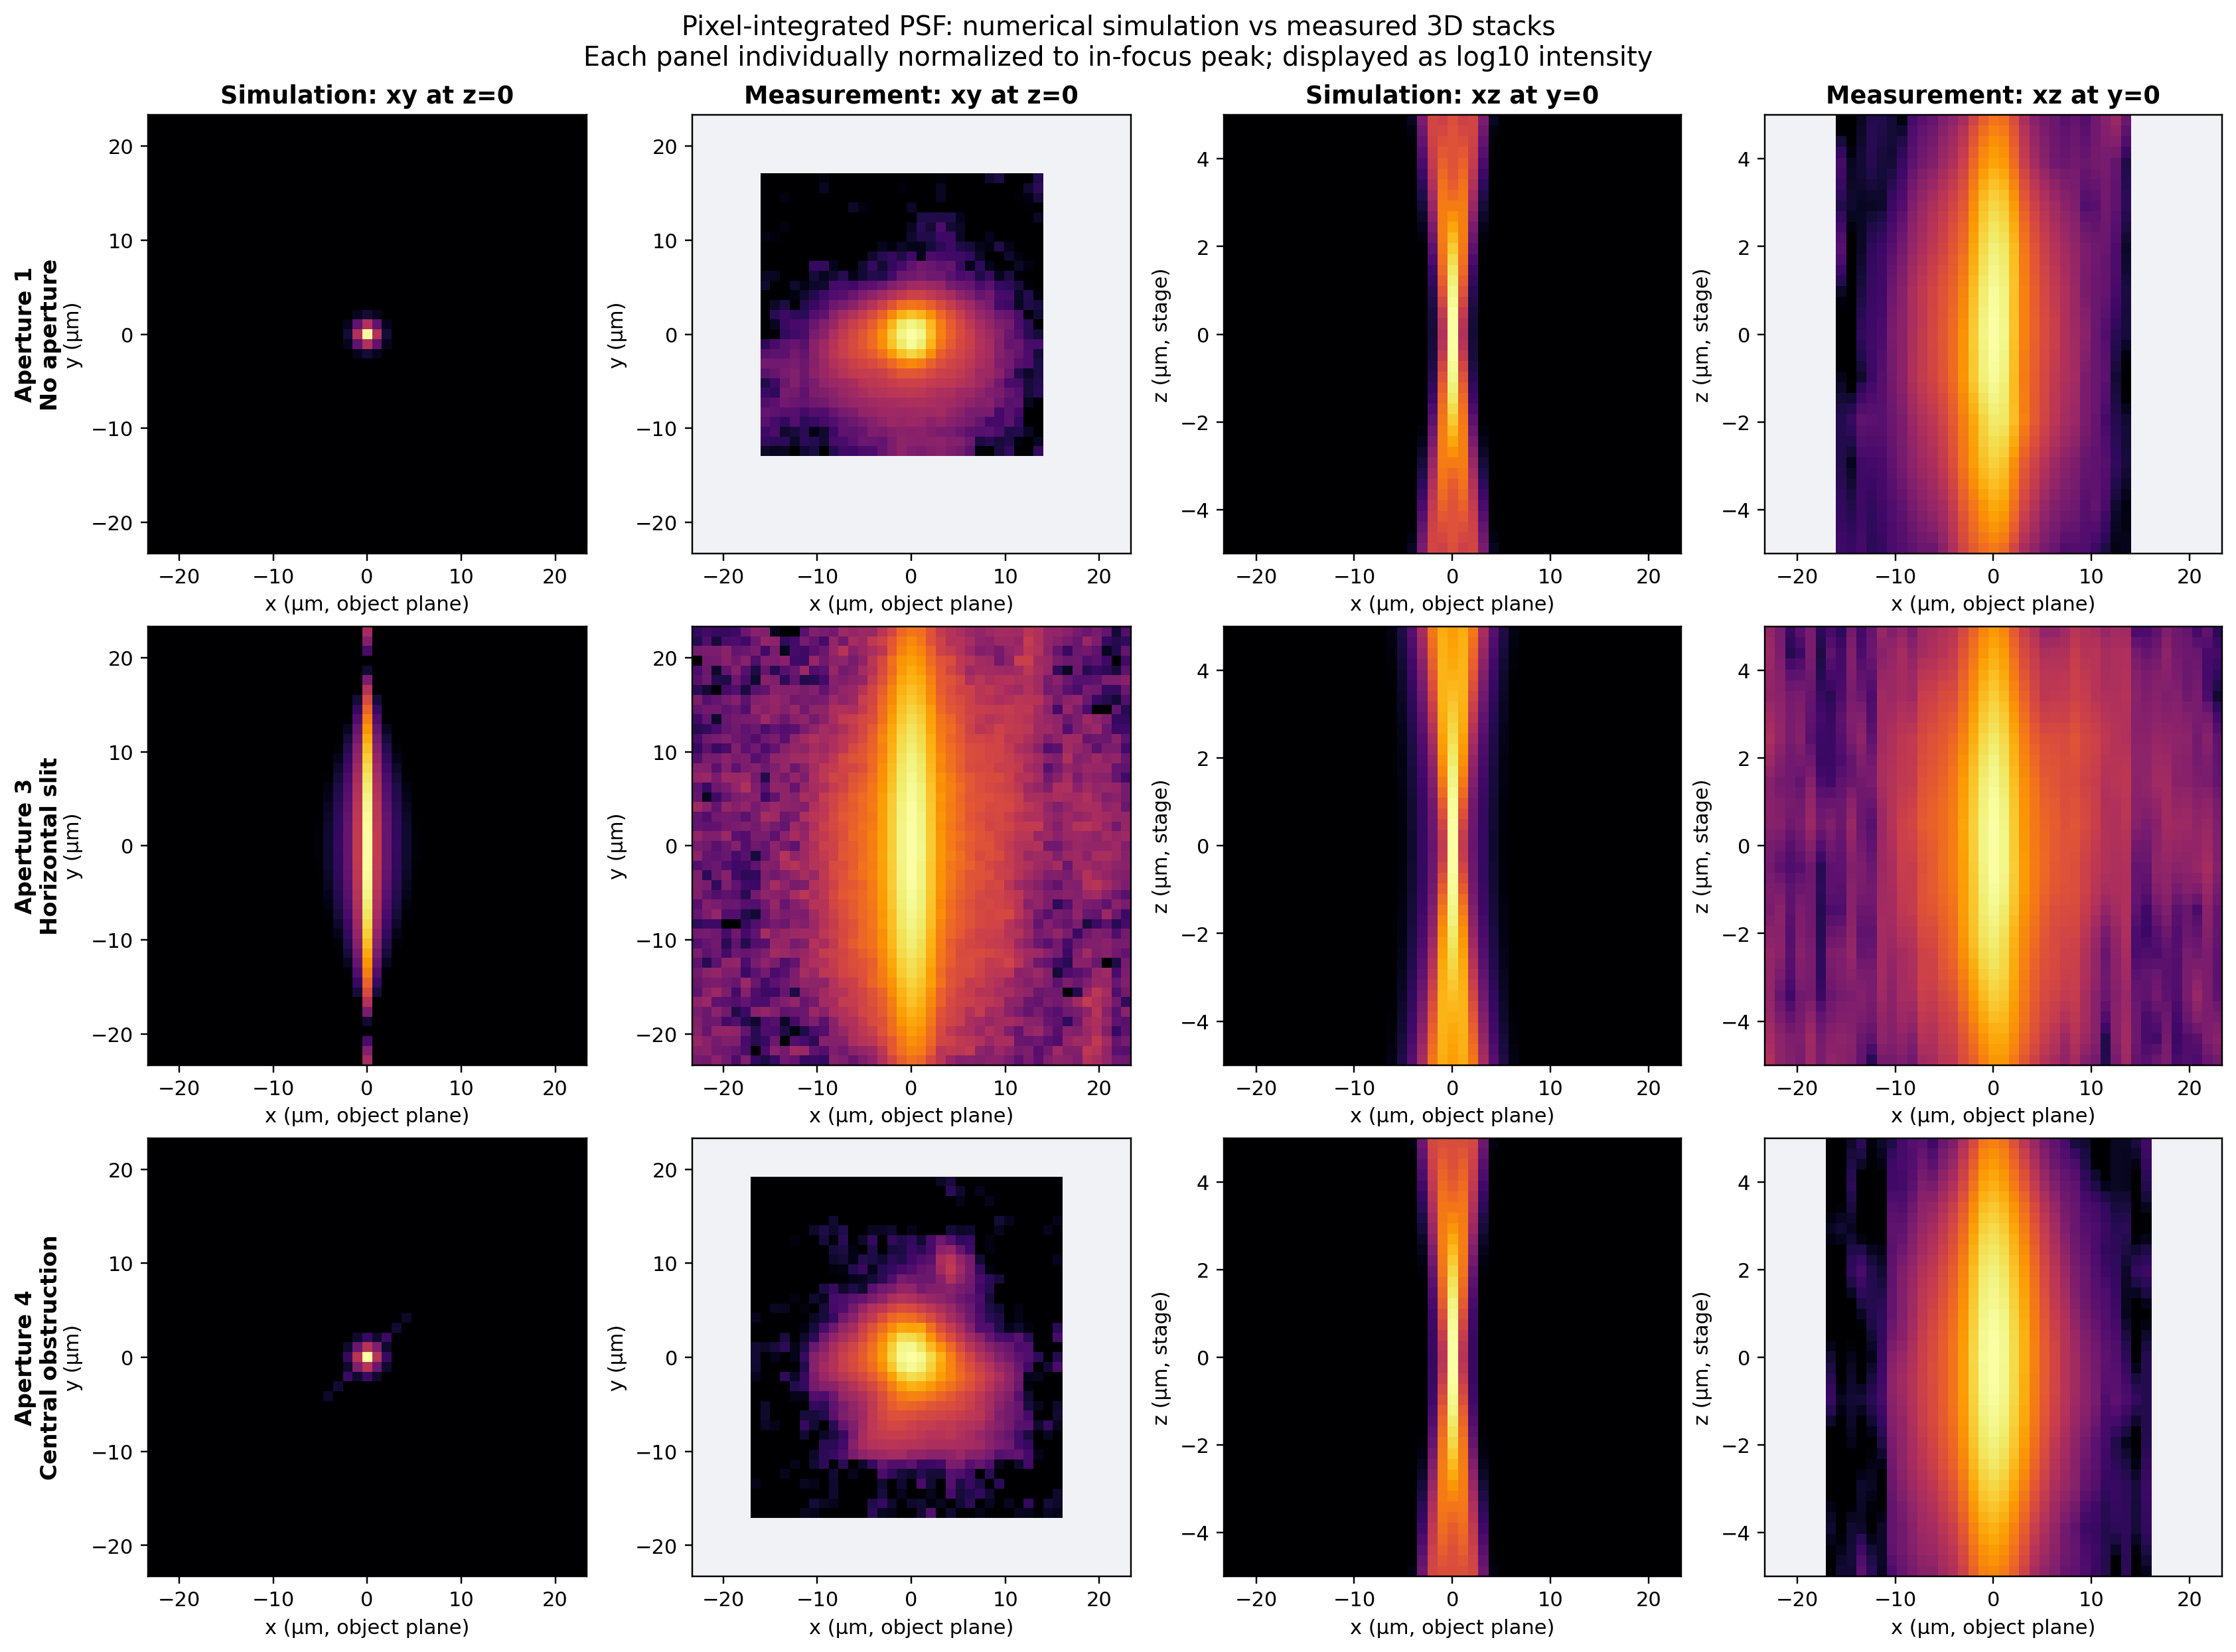

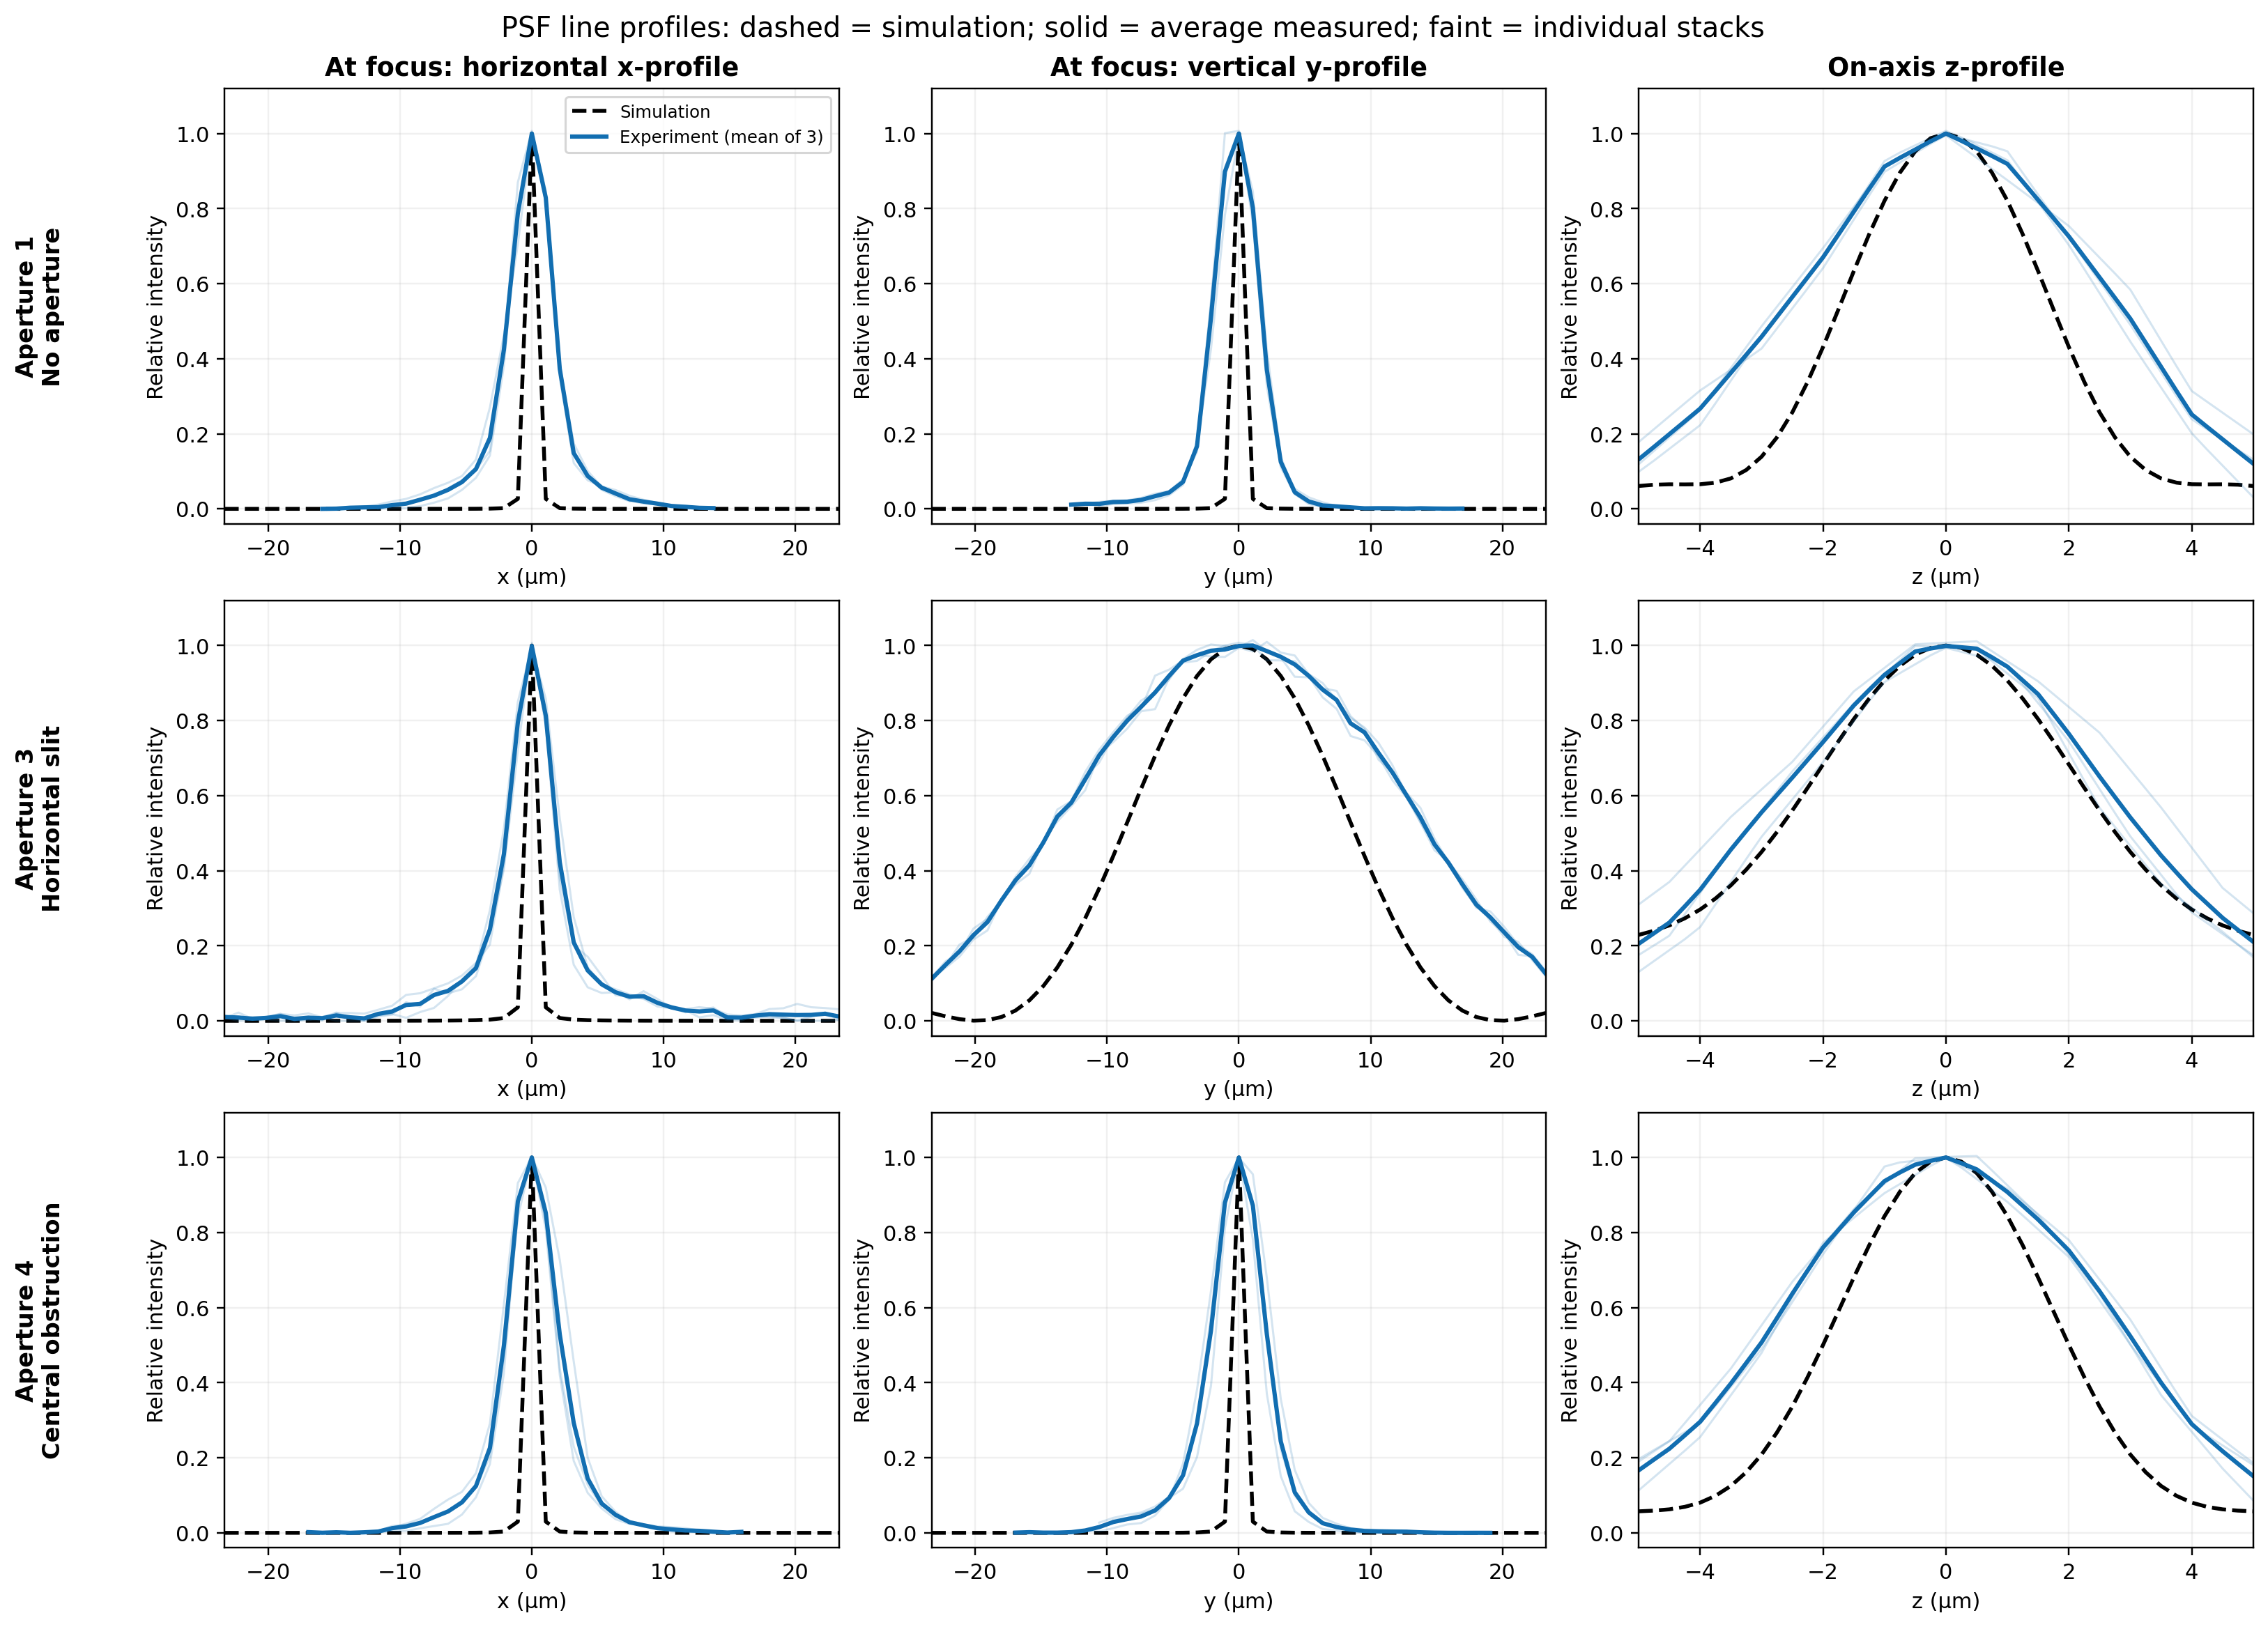

In [6]:
for filename in [
    'PSF_comparison/PSF_xy_xz_simulation_vs_experiment.png',
    'PSF_comparison/PSF_line_profiles.png']:
    display(Image(filename=str(root / filename), width=1050))

Figures 6–7. Comparison of simulated and measured xy/xz PSFs and x/y/z profiles. Intensities are normalized to compare shapes.

Approximate full widths at half maximum (FWHM, µm):

| Pupil | Simulation x / y / z | Measurement x / y / z |
|:--|--:|--:|
| 1 — open | 1.46 / 1.46 / 3.67 | 4.01 / 4.18 / 5.86 |
| 3 — slit | 1.48 / 17.67 / 5.55 | 4.22 / 28.91 / 6.50 |
| 4 — obstruction | 1.46 / 1.46 / 4.02 | 4.71 / 4.81 / 6.15 |

The open pupil gives an approximately symmetric lateral PSF. The slit broadens the PSF vertically, while the central obstruction changes its sidelobes. Measured PSFs are generally broader because of aberrations, alignment, bead size, and sampling. The widths are approximate owing to incomplete z-frame indexing and uncertain model scaling.